# 01 – Exploration des données : gravité des accidents corporels (BAAC)
**Objectif** : classer la gravité d'un accident corporel (`grav_max` = gravité de l'usager le plus touché) à partir de ses caractéristiques.
**Source** : data.gouv.fr – BAAC (Licence Ouverte). Année de travail : 2023.
**Une ligne = un accident** (54 822 accidents). Le jeu est construit par `src/build_dataset.py` (`make dataset`) à partir des 4 tables brutes.


In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import chi2_contingency
from pathlib import Path
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OrdinalEncoder
sns.set_theme(style="whitegrid"); pd.set_option("display.max_columns", 60)
YEAR = 2023
LOCAL = Path("../data/processed")/f"accidents_{YEAR}.csv"
URL = f"https://raw.githubusercontent.com/cyannure/aaa/main/data/processed/accidents_{YEAR}.csv"
# Couleurs : la gravité est ordonnée, donc une seule teinte du clair (léger) au foncé (tué) ;
# même logique pour les heatmaps (bleu clair = 0, bleu foncé = 1)
COULEURS_GRAV = {"leger": "#86b6ef", "hospitalise": "#2a78d6", "tue": "#104281"}
BLEU = "#2a78d6"
BLEUS = LinearSegmentedColormap.from_list("bleus", ["#cde2fb", "#86b6ef", "#2a78d6", "#1c5cab", "#0d366b"])

## 1. Chargement
20 features en 4 groupes :
- **Accident** : `heure`, `week_end`, `lum`, `atm`, `agg`, `int`, `col`
- **Lieu** (1re ligne de `lieux` par accident) : `catr`, `vma`, `surf`, `situ`, `nbv`
- **Conducteurs** (agrégés) : `age_cond_max`, `part_cond_hommes`, `part_cond_loisirs`, `part_cond_proteges`
- **Véhicules** (agrégés) : `veh_vulnerable`, `choc_avant`, `manv_risquee`, `pieton_heurte`

Les codes BAAC sont lus comme des nombres mais sont **catégoriels** : on les convertit.

In [2]:
CAT = ["lum","atm","agg","int","col","catr","surf","situ","veh_vulnerable"]
BIN = ["week_end","choc_avant","manv_risquee","pieton_heurte"]
NUM = ["heure","vma","nbv","age_cond_max","part_cond_hommes","part_cond_loisirs","part_cond_proteges"]
TARGET = "grav_max"
df = pd.read_csv(LOCAL if LOCAL.exists() else URL, dtype={c: str for c in CAT})
df[CAT] = df[CAT].astype("category")
df[TARGET] = pd.Categorical(df[TARGET], categories=["leger","hospitalise","tue"], ordered=True)
print(df.shape); df.head()

(54822, 21)


,heure,week_end,lum,atm,agg,int,col,catr,surf,situ,vma,nbv,age_cond_max,part_cond_hommes,part_cond_loisirs,part_cond_proteges,veh_vulnerable,choc_avant,manv_risquee,pieton_heurte,grav_max
0,6.0,1,1,2,2,4,7,4,2,1,30.0,2.0,45.0,1.000000,1.0,1.0,2rm_3rm,0,0,0,leger
1,5.0,1,5,3,2,1,6,3,2,1,50.0,3.0,26.0,0.000000,0.0,1.0,vl_vu,1,0,1,hospitalise
2,20.0,1,1,2,2,3,1,3,2,1,50.0,4.0,39.0,0.500000,NaN,1.0,2rm_3rm,1,0,0,hospitalise
3,23.0,1,5,3,2,1,5,2,2,1,50.0,4.0,55.0,0.666667,0.0,1.0,vl_vu,1,0,0,leger
4,0.0,1,5,3,2,2,3,4,2,1,30.0,1.0,22.0,0.500000,0.0,1.0,vl_vu,1,0,0,leger


### Mise de côté du test set
On sépare 20 % des accidents **avant toute exploration**, stratifiés sur la cible, pour éviter le biais de *data snooping* (chapitre 02) : toute l'analyse qui suit et tous les `fit` (imputation, encodage…) se font sur `train` ; `test` ne sert qu'à l'évaluation finale.

In [3]:
train, test = train_test_split(df, test_size=0.2, stratify=df[TARGET], random_state=42)
print("train :", train.shape, " test :", test.shape)
pd.DataFrame({"train": train[TARGET].value_counts(normalize=True), "test": test[TARGET].value_counts(normalize=True)}).round(3)

train : (43857, 21)  test : (10965, 21)


,train,test
grav_max,,
leger,0.639,0.639
hospitalise,0.302,0.302
tue,0.058,0.058


## 2. Métadonnées, types et valeurs manquantes

In [4]:
info = pd.DataFrame({"type": train.dtypes.astype(str), "nunique": train.nunique(),
                     "na_%": (train.isna().mean()*100).round(1)}).sort_values("na_%", ascending=False)
info

,type,nunique,na_%
part_cond_loisirs,float64,16,21.3
part_cond_proteges,float64,8,10.5
nbv,float64,12,6.3
vma,float64,19,3.8
age_cond_max,float64,95,1.4
part_cond_hommes,float64,19,1.3
veh_vulnerable,category,4,0.3
situ,category,7,0.1
surf,category,9,0.1
heure,float64,24,0.0


### Valeurs manquantes et gravité
Le fait qu'une valeur manque est-il lié à la gravité ? Si oui, l'absence est une information en soi, que l'imputation ne doit pas effacer.

In [5]:
lignes = []
for c in [c for c in train.columns if train[c].isna().any()]:
    manq = train[c].isna()
    lignes.append({"variable": c, "manquants_%": manq.mean()*100,
                   "tues_si_manquant_%": (train.loc[manq, TARGET] == "tue").mean()*100,
                   "tues_sinon_%": (train.loc[~manq, TARGET] == "tue").mean()*100,
                   "graves_si_manquant_%": train.loc[manq, TARGET].isin(["hospitalise", "tue"]).mean()*100,
                   "graves_sinon_%": train.loc[~manq, TARGET].isin(["hospitalise", "tue"]).mean()*100})
pd.DataFrame(lignes).set_index("variable").sort_values("manquants_%", ascending=False).round(1)

,manquants_%,tues_si_manquant_%,tues_sinon_%,graves_si_manquant_%,graves_sinon_%
variable,,,,,
part_cond_loisirs,21.3,3.6,6.5,27.2,38.5
part_cond_proteges,10.5,7.2,5.7,32.4,36.5
nbv,6.3,3.3,6.0,24.7,36.9
vma,3.8,7.4,5.8,41.2,35.9
age_cond_max,1.4,3.2,5.9,23.7,36.3
part_cond_hommes,1.3,3.2,5.9,23.3,36.3
veh_vulnerable,0.3,7.2,5.8,40.3,36.1
situ,0.1,5.0,5.8,47.5,36.1
surf,0.1,8.8,5.8,55.9,36.1


**Interprétation.**
- `part_cond_loisirs` (≈ 21 %) : le motif du trajet est souvent non renseigné par les forces de l'ordre ; ces accidents sont nettement moins graves.
- `part_cond_proteges` (≈ 10 %) : équipement « non déterminable » ; ces accidents sont un peu plus souvent mortels.
- `nbv` (≈ 6 %, dont les « 0 voie » de la base) et `vma` (≈ 4 %) : informations de voirie absentes ; `nbv` manquant va avec des accidents moins graves, `vma` manquant avec des accidents plus graves.
- `age_cond_max` et `part_cond_hommes` (≈ 1 %) : âge et sexe inconnus, a priori des conducteurs en fuite (conducteur fictif sans information selon la documentation BAAC) ; ces accidents sont deux fois moins souvent mortels.
- `veh_vulnerable`, `surf`, `situ`, `col`, `int`, `atm`, `lum` (< 0,5 %, quelques accidents pour les quatre derniers) : négligeable.

Les valeurs ne manquent donc **pas au hasard** : l'absence elle-même est liée à la gravité.

### Stratégie retenue
- **`vma`** : médiane de `vma` **dans le même type de zone** (`agg`) : la limite usuelle est 80 km/h hors agglomération et 50 km/h en agglomération, une valeur unique serait fausse pour l'un des deux groupes. Plus un indicateur `vma_manquant`.
- **Autres numériques** : médiane + indicateur de manquant (`missingindicator_<variable>`), puisque l'absence est liée à la gravité.
- **Catégorielles** : valeur la plus fréquente, sans indicateur (moins de 0,5 % de manquants).
- Tout est appris sur `train` (`fit`) puis appliqué tel quel au test (`transform`), à l'intérieur du pipeline.

`KNNImputer` et les NaN natifs de `HistGradientBoosting` seront comparés avec les modèles.

In [6]:
class ImputeurParGroupe(BaseEstimator, TransformerMixin):
    """Remplace les NaN de `col` par la médiane de `col` dans le groupe `by`, apprise au fit (donc sur le train),
    et ajoute l'indicateur `<col>_manquant`."""
    def __init__(self, col="vma", by="agg"):
        self.col, self.by = col, by

    def fit(self, X, y=None):
        self.medianes_ = X.groupby(self.by, observed=True)[self.col].median()
        self.mediane_globale_ = X[self.col].median()  # si le groupe est inconnu
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        return self

    def transform(self, X):
        X = X.copy()
        manquant = X[self.col].isna()
        valeur_du_groupe = X[self.by].astype(object).map(self.medianes_).astype(float)
        X[self.col] = X[self.col].fillna(valeur_du_groupe).fillna(self.mediane_globale_)
        X[f"{self.col}_manquant"] = manquant.astype(int)
        return X

    def get_feature_names_out(self, input_features=None):  # nécessaire pour set_output et les pipelines
        return np.append(self.feature_names_in_, f"{self.col}_manquant")

imputation = ColumnTransformer([
    ("num", SimpleImputer(strategy="median", add_indicator=True), NUM),
    ("cat", SimpleImputer(strategy="most_frequent"), CAT),
], remainder="passthrough", verbose_feature_names_out=False)
imputation_nan = make_pipeline(ImputeurParGroupe("vma", "agg"), imputation).set_output(transform="pandas")

X_train = train.drop(columns=TARGET)
X_imp = imputation_nan.fit_transform(X_train)
print("Médiane de vma apprise pour chaque valeur de agg :", imputation_nan[0].medianes_.to_dict())
print("NaN restants :", int(X_imp.isna().sum().sum()))
print("Colonnes ajoutées :", [c for c in X_imp.columns if c not in X_train.columns])

Médiane de vma apprise pour chaque valeur de agg : {'1': 80.0, '2': 50.0}
NaN restants : 0
Colonnes ajoutées : ['missingindicator_nbv', 'missingindicator_age_cond_max', 'missingindicator_part_cond_hommes', 'missingindicator_part_cond_loisirs', 'missingindicator_part_cond_proteges', 'vma_manquant']


In [7]:
# Exemples avant / après : un accident sans vma par type de zone, un sans part_cond_loisirs
ex = (X_train[X_train["vma"].isna()].groupby("agg", observed=True).head(1).index.tolist()
      + X_train[X_train["part_cond_loisirs"].isna()].index[:1].tolist())
pd.concat({"avant": X_train.loc[ex, ["agg", "vma", "part_cond_loisirs"]],
           "après": X_imp.loc[ex, ["vma", "vma_manquant", "part_cond_loisirs", "missingindicator_part_cond_loisirs"]]}, axis=1)

avant                         après                                 \
        agg   vma part_cond_loisirs   vma vma_manquant part_cond_loisirs   
40171     2   NaN               1.0  50.0            1               1.0   
41295     1   NaN               1.0  80.0            1               1.0   
26667     2  50.0               NaN  50.0            0               0.5   

                                          
      missingindicator_part_cond_loisirs  
40171                                0.0  
41295                                0.0  
26667                                1.0

## 3. Variable cible `grav_max`
Pas de classe « indemne » : un accident corporel a au moins un blessé.

grav_max
leger          0.639
hospitalise    0.302
tue            0.058
Name: proportion, dtype: float64


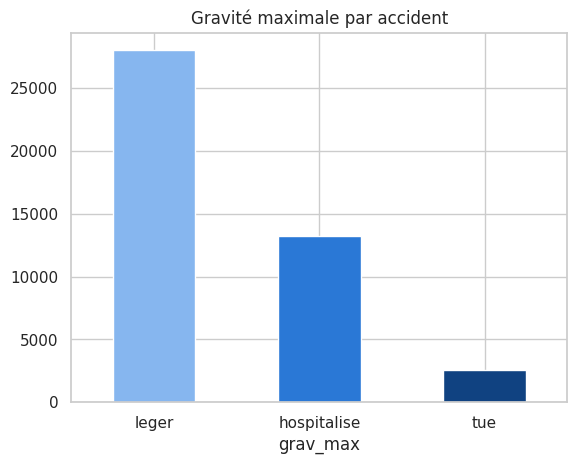

In [8]:
print(train[TARGET].value_counts(normalize=True).round(3))
train[TARGET].value_counts().sort_index().plot.bar(color=list(COULEURS_GRAV.values()), rot=0, title="Gravité maximale par accident"); plt.show()

## 4. Distributions des variables
Histogrammes pour les 7 numériques, effectifs par modalité pour les 4 binaires et les 9 catégorielles (NaN inclus).

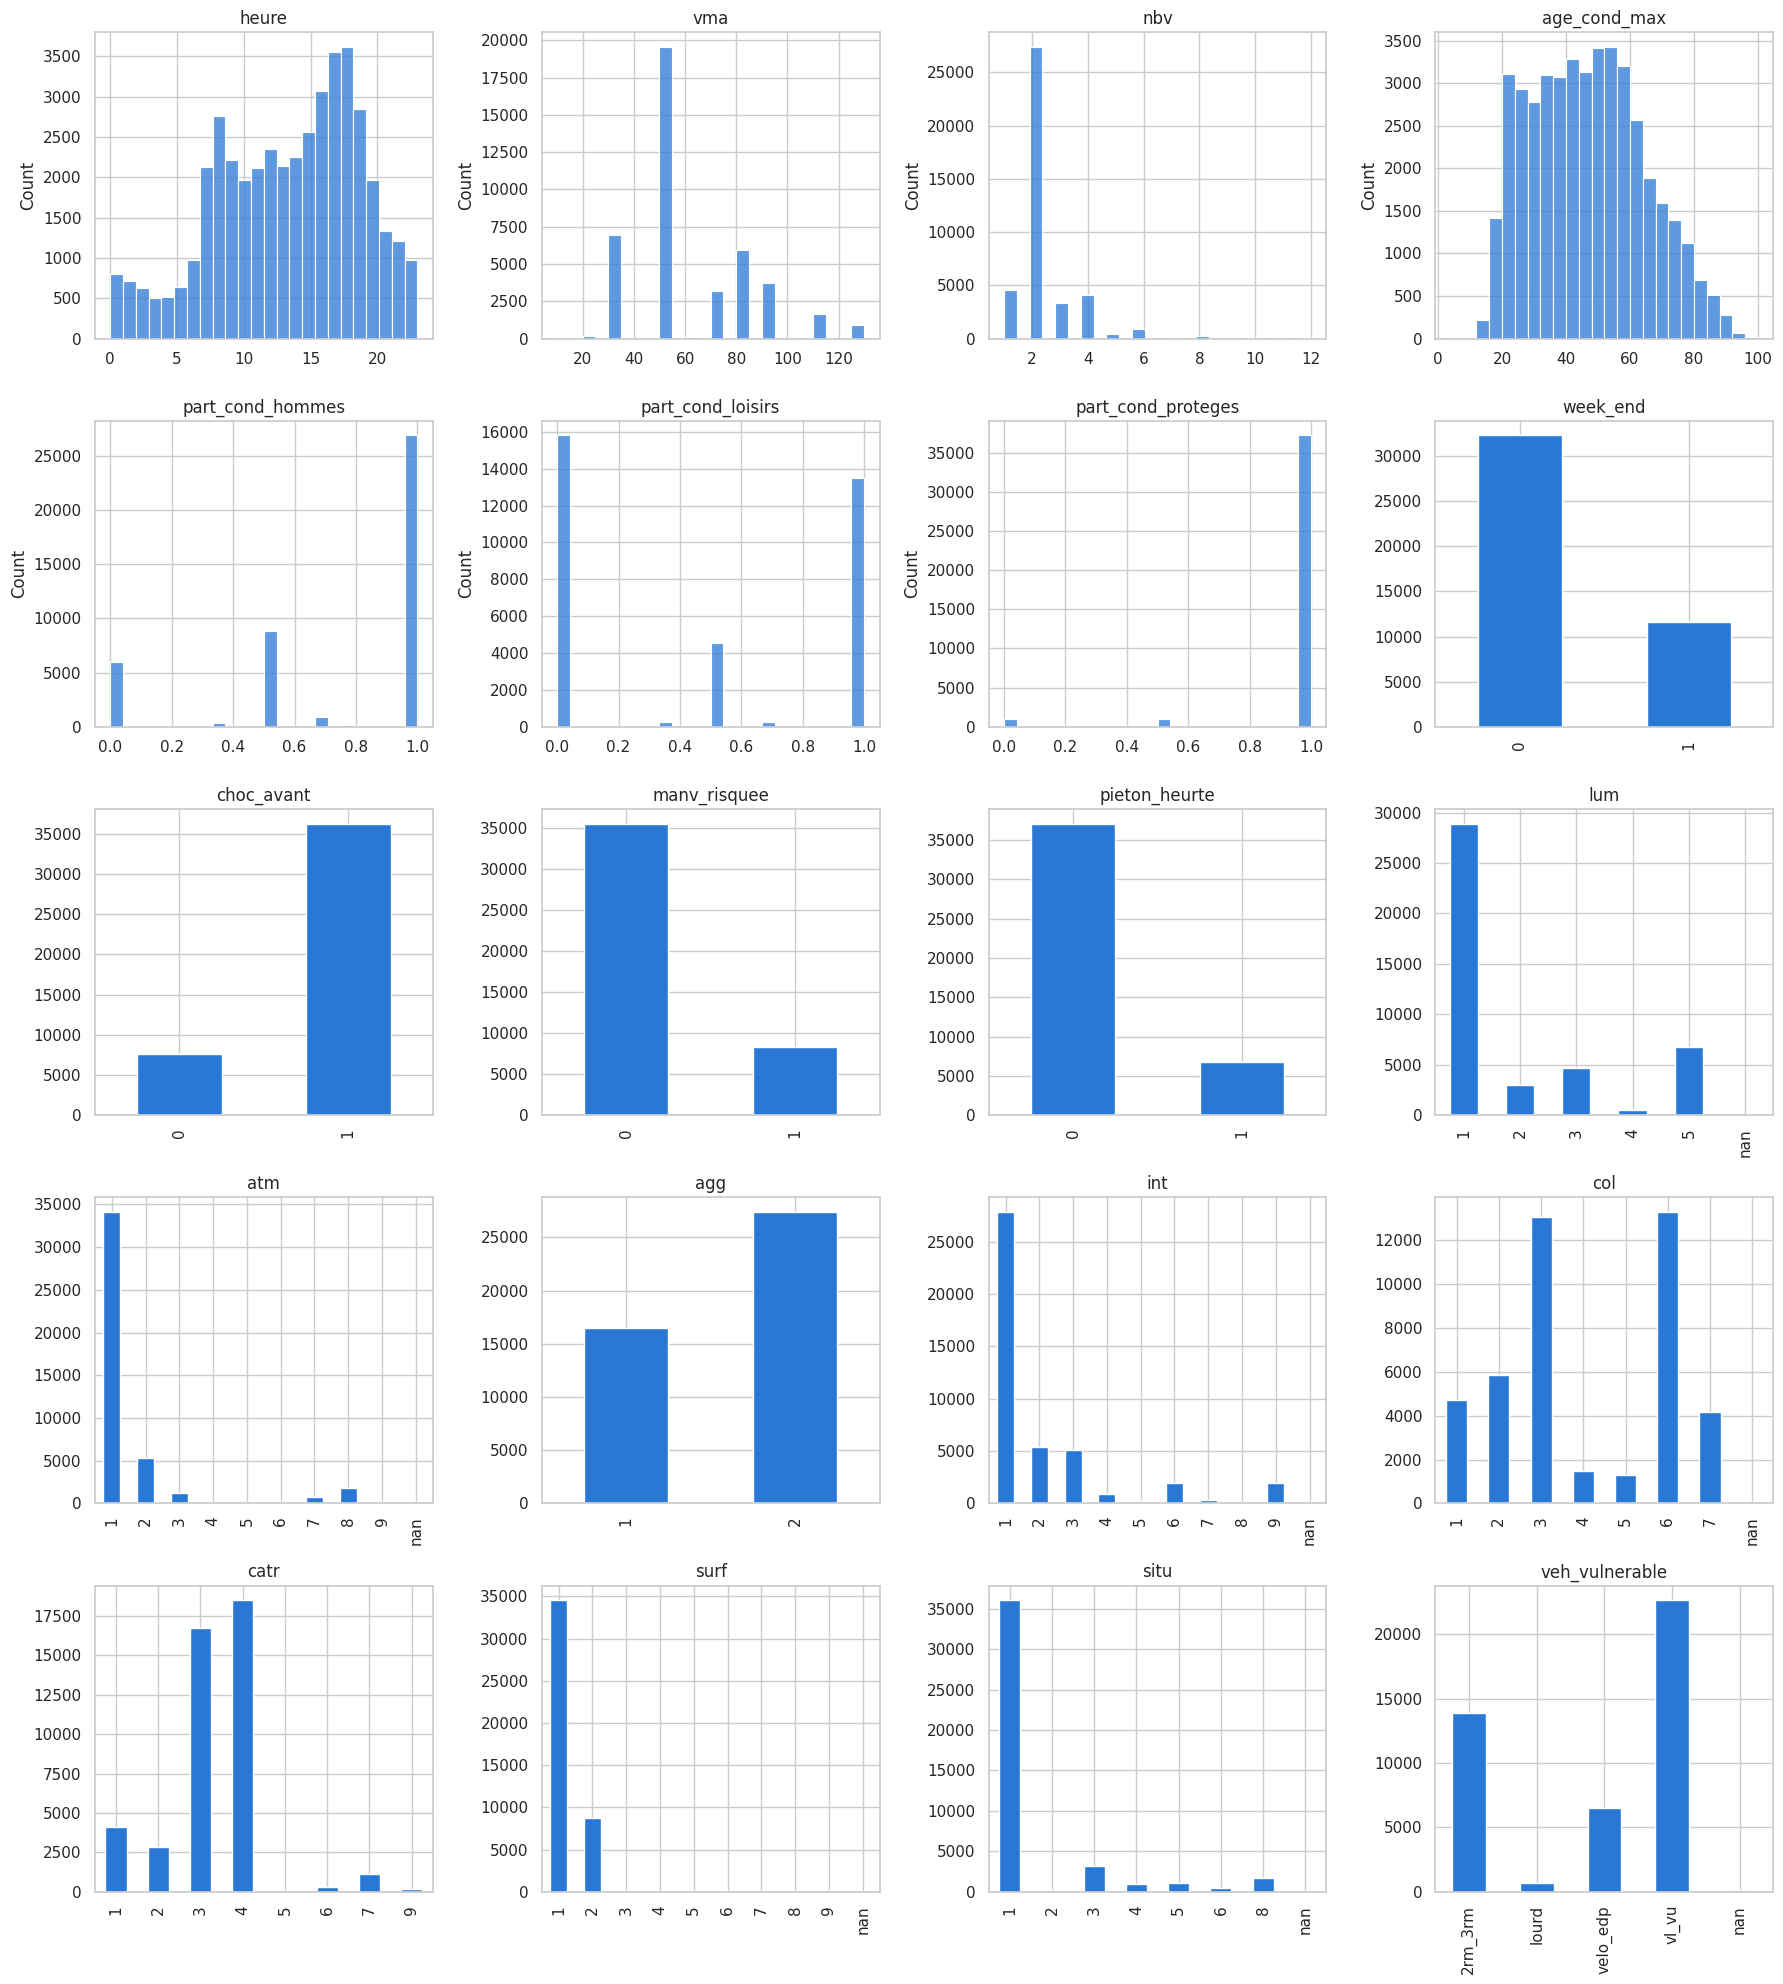

In [9]:
FEATURES = NUM + BIN + CAT
fig, axes = plt.subplots(5, 4, figsize=(18,20))
for a, c in zip(axes.ravel(), FEATURES):
    if c in NUM:
        sns.histplot(train[c].dropna(), bins=24, color=BLEU, ax=a)
    else:
        train[c].value_counts(dropna=False).sort_index().plot.bar(color=BLEU, ax=a)
    a.set_title(c); a.set_xlabel("")
plt.tight_layout(); plt.show()

### Lien avec la cible
Pour chaque modalité des variables catégorielles et binaires : répartition des classes de `grav_max`.

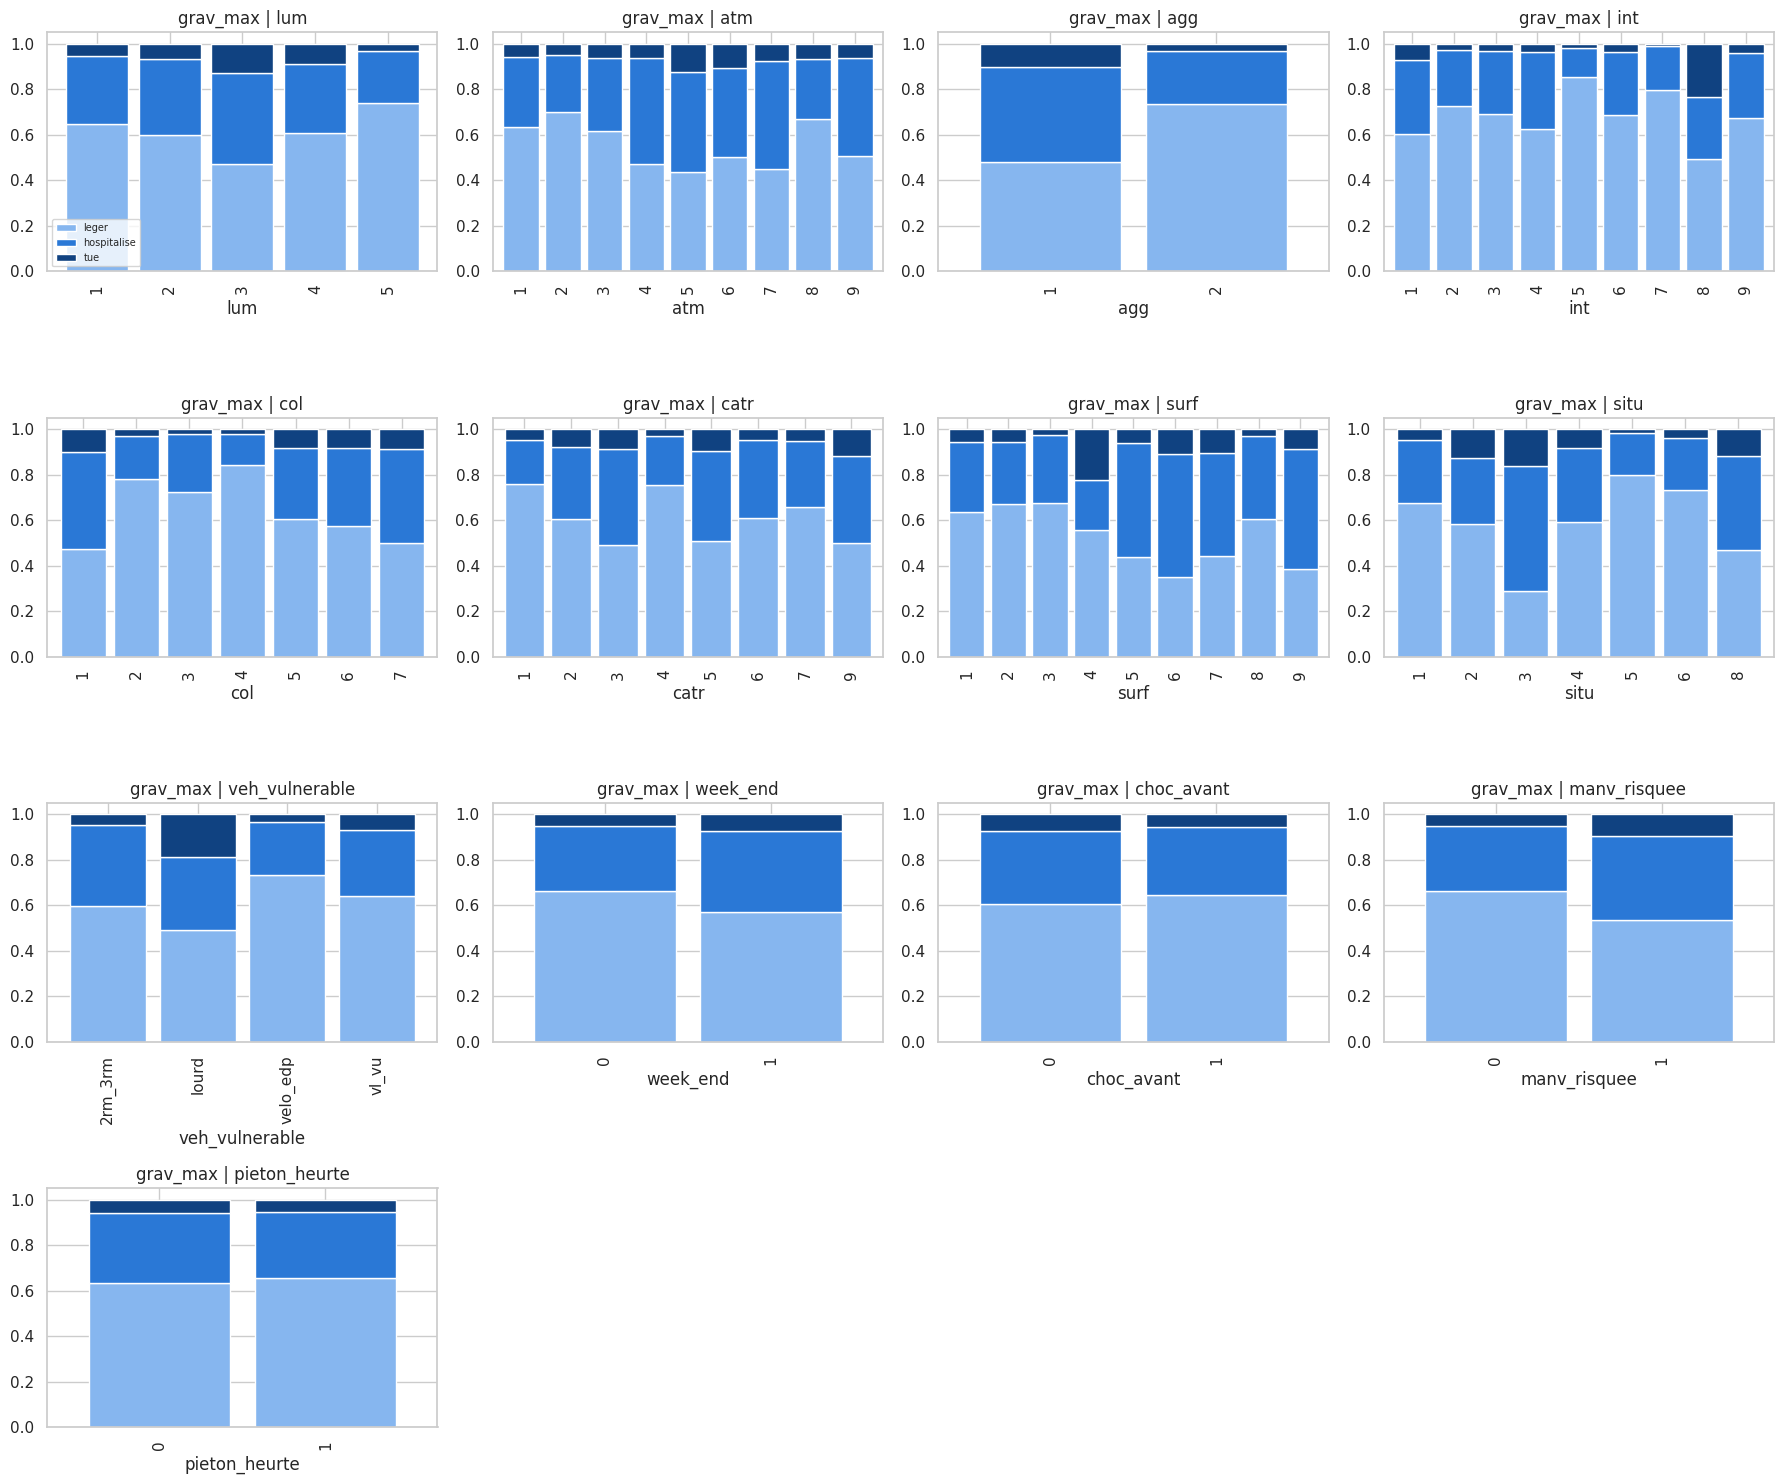

In [10]:
cols = CAT + BIN
fig, axes = plt.subplots(4, 4, figsize=(18,15))
for a, c in zip(axes.ravel(), cols):
    pd.crosstab(train[c], train[TARGET], normalize="index").plot.bar(stacked=True, color=COULEURS_GRAV, width=0.85, edgecolor="white", linewidth=1, ax=a, legend=False, title=f"grav_max | {c}")
for a in axes.ravel()[len(cols):]: a.axis("off")
axes[0,0].legend(fontsize=7); plt.tight_layout(); plt.show()

### Gravité selon les variables numériques
- `age_cond_max` : distribution par classe (boxplots ; les points isolés sont les valeurs aberrantes au sens de la règle 1,5 × écart interquartile).
- `heure`, `vma`, `nbv` : peu de valeurs distinctes, donc même lecture que pour les catégorielles (répartition des classes pour chaque valeur ; valeurs présentes dans au moins 200 accidents).
- Parts de conducteurs : moyenne pour chaque classe.

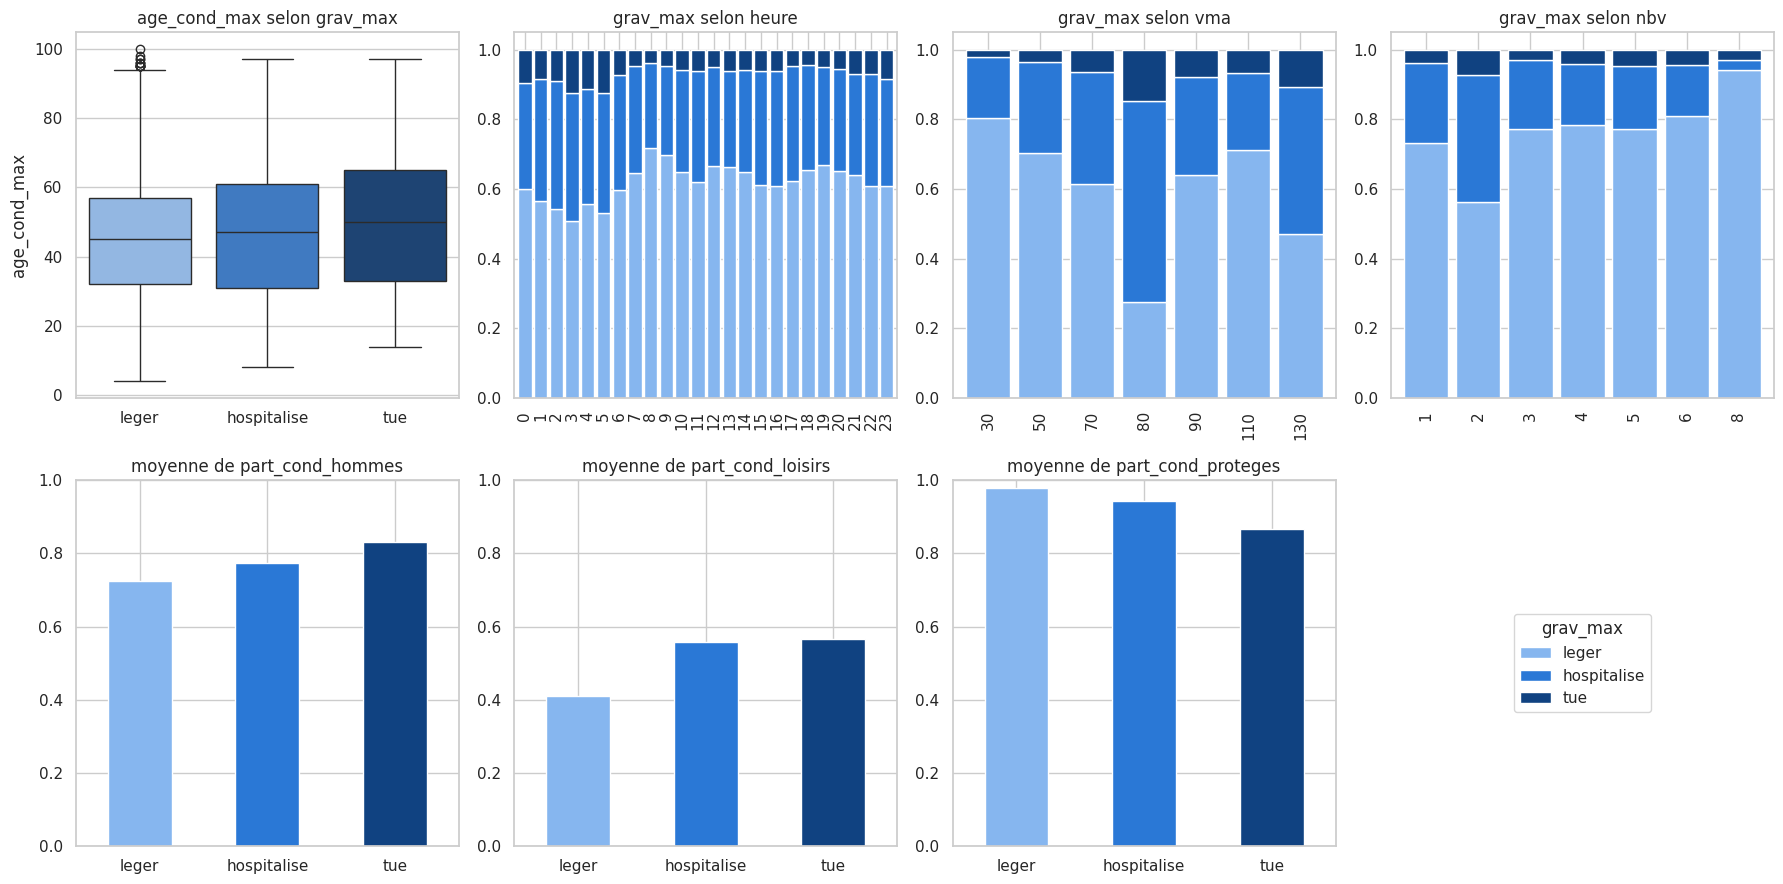

Accidents dont le conducteur le plus âgé a moins de 14 ans : 51


In [11]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
ax = axes.ravel()
sns.boxplot(data=train, x=TARGET, y="age_cond_max", hue=TARGET, palette=COULEURS_GRAV, legend=False, ax=ax[0])
ax[0].set_title("age_cond_max selon grav_max"); ax[0].set_xlabel("")
for a, c in zip(ax[1:4], ["heure", "vma", "nbv"]):
    n = train[c].value_counts()
    sous = train[train[c].isin(n[n >= 200].index)]
    pd.crosstab(sous[c].astype(int), sous[TARGET], normalize="index").plot.bar(
        stacked=True, color=COULEURS_GRAV, width=0.85, edgecolor="white", linewidth=1, ax=a, legend=False, title=f"grav_max selon {c}")
    a.set_xlabel("")
for a, c in zip(ax[4:7], ["part_cond_hommes", "part_cond_loisirs", "part_cond_proteges"]):
    m = train.groupby(TARGET, observed=True)[c].mean()
    m.plot.bar(color=[COULEURS_GRAV[k] for k in m.index], rot=0, ax=a, title=f"moyenne de {c}")
    a.set_xlabel(""); a.set_ylim(0, 1)
ax[7].axis("off")
ax[7].legend(*ax[1].get_legend_handles_labels(), title="grav_max", loc="center")
plt.tight_layout(); plt.show()
print("Accidents dont le conducteur le plus âgé a moins de 14 ans :", int((train["age_cond_max"] < 14).sum()))

**Interprétation.**
- `vma` : lien fort mais **non monotone**. Les accidents les plus graves sont à 80 km/h (routes hors agglomération : 14,8 % de tués, 57,6 % d'hospitalisés), pas à 130 km/h (autoroutes, mieux aménagées : 10,6 % de tués). Un modèle linéaire qui traiterait `vma` comme un nombre (« plus vite = plus grave ») passerait à côté : il faudra l'encoder en catégories pour les modèles linéaires ; les arbres trouvent ces seuils seuls.
- `heure` : la nuit (0 h à 6 h) est nettement plus grave, 8 h et 9 h le sont le moins. L'effet est **cyclique** (23 h ressemble à 0 h, pas à 12 h) : d'où un encodage sin/cos plutôt que l'heure brute.
- `nbv` : les routes à 2 voies (souvent bidirectionnelles, hors ville) sont les plus graves ; les grandes voies urbaines (6 voies et plus) le sont le moins.
- `age_cond_max` : un peu plus élevé quand l'accident est mortel (médiane 50 ans, contre 45 pour les accidents légers). 51 accidents n'ont que des conducteurs de moins de 14 ans : 43 à vélo ou en trottinette, plausibles et gardés ; 3 en voiture, probablement des erreurs de saisie, en nombre négligeable.
- Parts de conducteurs : quand la gravité augmente, la part d'hommes monte (0,72 → 0,83), celle des trajets de loisirs aussi (0,41 → 0,57), et celle des conducteurs protégés baisse (0,98 → 0,87).

## 5. Corrélations et sélection de variables
### Associations entre variables
La corrélation de Pearson ne convient qu'aux variables numériques. On utilise une mesure adaptée à chaque paire, toutes comprises entre 0 (aucun lien) et 1 (lien parfait) :
- **numérique – numérique** : |Spearman| (corrélation des rangs, robuste aux valeurs aberrantes, en valeur absolue pour rester entre 0 et 1) ;
- **catégorielle – numérique** : rapport de corrélation η (part de la variance de la numérique expliquée par les catégories) ;
- **catégorielle – catégorielle** : V de Cramér (dérivé du χ²).

Les binaires sont traitées comme catégorielles. La cible est incluse (dernière ligne). Calcul sur le train, valeurs manquantes exclues paire par paire.

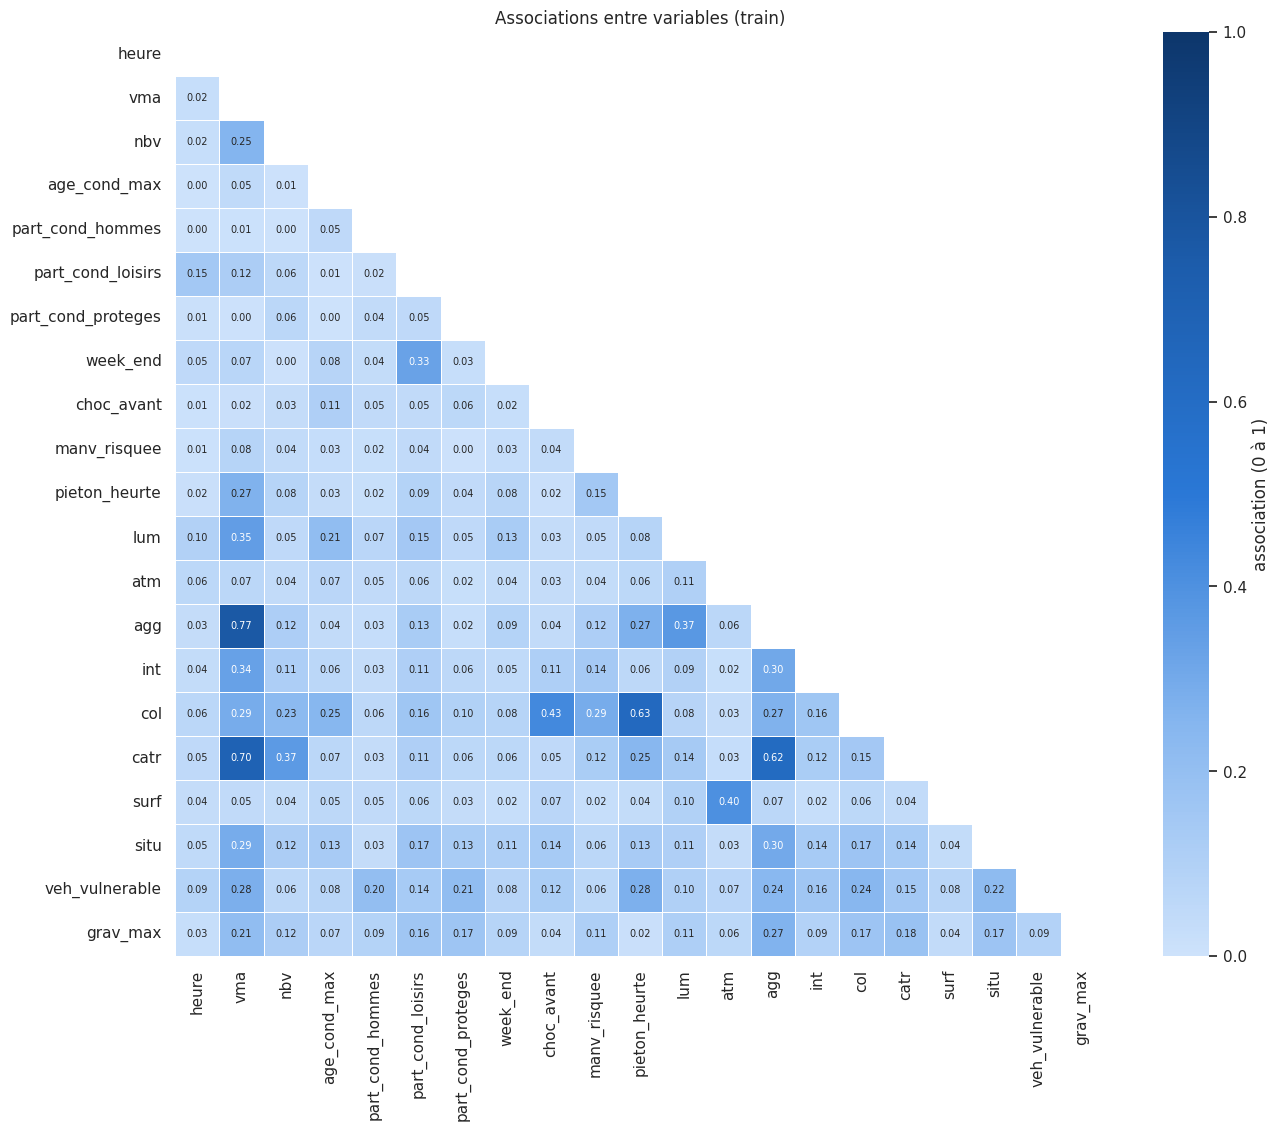

In [12]:
def cramers_v(x, y):
    d = pd.DataFrame({"x": x, "y": y}).dropna().astype(str)
    t = pd.crosstab(d["x"], d["y"])
    chi2 = chi2_contingency(t, correction=False)[0]
    return np.sqrt(chi2 / (t.to_numpy().sum() * (min(t.shape) - 1)))

def rapport_correlation(cat, num):
    d = pd.DataFrame({"c": cat, "x": num}).dropna()
    g = d.groupby("c", observed=True)["x"].agg(["mean", "count"])
    inter = (g["count"] * (g["mean"] - d["x"].mean()) ** 2).sum()
    return np.sqrt(inter / ((d["x"] - d["x"].mean()) ** 2).sum())

def association(a, b):
    if a in NUM and b in NUM:
        return abs(train[a].corr(train[b], method="spearman"))
    if a in NUM:
        return rapport_correlation(train[b], train[a])
    if b in NUM:
        return rapport_correlation(train[a], train[b])
    return cramers_v(train[a], train[b])

VARS = NUM + BIN + CAT + [TARGET]
assoc = pd.DataFrame(1.0, index=VARS, columns=VARS)
for i, a in enumerate(VARS):
    for b in VARS[:i]:
        assoc.loc[a, b] = assoc.loc[b, a] = association(a, b)

plt.figure(figsize=(15, 12))
with sns.axes_style("white"):  # pas de grille sous la heatmap
    sns.heatmap(assoc, mask=np.triu(np.ones_like(assoc, dtype=bool)), cmap=BLEUS, vmin=0, vmax=1,
                annot=True, fmt=".2f", annot_kws={"size": 7}, linewidths=0.5, cbar_kws={"label": "association (0 à 1)"})
plt.title("Associations entre variables (train)"); plt.show()

In [13]:
paires = assoc.where(np.tril(np.ones(assoc.shape, dtype=bool), k=-1)).stack()
print("Paires de variables les plus liées (hors cible) :")
print(paires.drop(TARGET, level=0).sort_values(ascending=False).head(10).round(2).to_string())
print("\nAssociation de chaque variable avec grav_max :")
print(assoc[TARGET].drop(TARGET).sort_values(ascending=False).round(3).to_string())

Paires de variables les plus liées (hors cible) :
agg   vma              0.77
catr  vma              0.70
col   pieton_heurte    0.63
catr  agg              0.62
col   choc_avant       0.43
surf  atm              0.40
agg   lum              0.37
catr  nbv              0.37
lum   vma              0.35
int   vma              0.34

Association de chaque variable avec grav_max :
agg                   0.265
vma                   0.212
catr                  0.184
situ                  0.170
col                   0.170
part_cond_proteges    0.167
part_cond_loisirs     0.157
nbv                   0.120
manv_risquee          0.112
lum                   0.112
veh_vulnerable        0.092
int                   0.091
part_cond_hommes      0.087
week_end              0.086
age_cond_max          0.068
atm                   0.059
surf                  0.041
choc_avant            0.037
heure                 0.025
pieton_heurte         0.017


**Interprétation.**
- **Redondances.** `vma`, `agg` et `catr` sont fortement liées (0,62 à 0,77) : en agglomération la limite est presque toujours 50 km/h, sur autoroute 110 ou 130. Liées mais pas identiques, chacune garde une part d'information propre. `col` et `pieton_heurte` (0,63) : 98 % des accidents avec piéton sont codés « autre collision » (`col = 6`). Redondances modérées : `col` et `choc_avant` (0,43), `surf` et `atm` (0,40 : pluie → chaussée mouillée).
- **Lien avec la cible.** `agg`, `vma`, `catr`, `situ`, `col`, `part_cond_proteges` et `part_cond_loisirs` sont les plus liées à `grav_max` (0,16 à 0,27). Aucune ne domine : la gravité dépend de nombreux facteurs, qu'il faudra combiner (modèles non linéaires, ensembles).
- **Variables faibles.** `pieton_heurte` (0,02), `heure` (0,03), `choc_avant` (0,04), `surf` (0,04). Pour `heure`, la mesure sous-estime le lien : η compare des moyennes, or les heures graves (la nuit) sont aux deux bouts de l'échelle 0-23. Pour `pieton_heurte`, le codage a été vérifié sur les tables brutes (98 % de concordance avec la présence d'un usager piéton) : les accidents avec piéton ne sont simplement pas plus graves que les autres.

## 6. Clustering non supervisé, conclusions
À compléter : réduction de dimension (ACP / ACM), K-Prototypes et K-Means vs `grav_max`, conclusions.

In [14]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, normalized_mutual_info_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler, OneHotEncoder

rng = np.random.RandomState(42)

X_imp = imputation_nan.fit_transform(train.drop(columns=TARGET))   # imputation apprise sur train
X_imp["heure_sin"] = np.sin(2*np.pi*X_imp["heure"]/24)
X_imp["heure_cos"] = np.cos(2*np.pi*X_imp["heure"]/24)
X_imp = X_imp.drop(columns="heure")

IND = [c for c in X_imp.columns if c.startswith("missingindicator_") or c == "vma_manquant"]
NUM_SC = [c for c in NUM if c != "heure"] + ["heure_sin", "heure_cos"]

encodage = ColumnTransformer([
    ("num", StandardScaler(), NUM_SC),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT),
    ("bin", "passthrough", BIN + IND),
], verbose_feature_names_out=False).set_output(transform="pandas")

Z = encodage.fit_transform(X_imp)
y_train = train[TARGET].to_numpy()
idx_s = rng.choice(len(Z), 8000, replace=False)     # sous-échantillon pour silhouette / graphes / DBSCAN
print("Matrice :", Z.shape)

Matrice : (43857, 78)


80 % de variance : 14 composantes (sur 78)
90 % de variance : 23 composantes (sur 78)
95 % de variance : 32 composantes (sur 78)


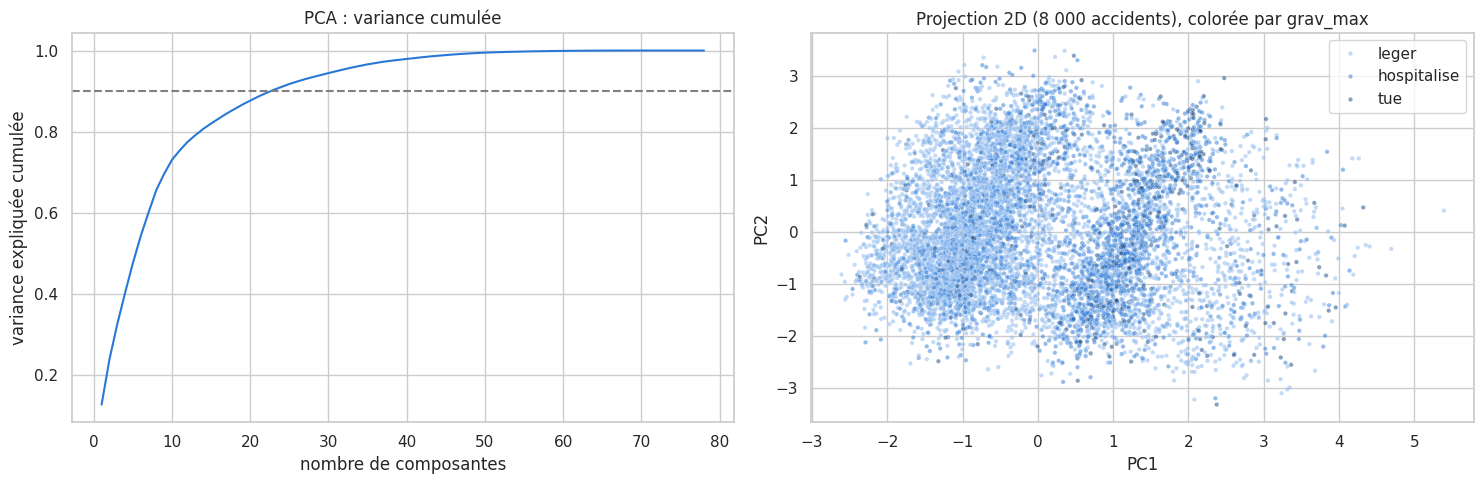


Variables qui pèsent le plus sur PC1 :
vma                  0.68
nbv                  0.31
agg_1                0.29
agg_2               -0.29
heure_cos            0.22
catr_4              -0.22
part_cond_loisirs    0.22
int_1                0.15

Variables qui pèsent le plus sur PC2 :
heure_cos            0.64
age_cond_max        -0.43
heure_sin           -0.32
part_cond_loisirs    0.30
lum_1               -0.23
vma                 -0.22
nbv                 -0.16
part_cond_hommes     0.15


In [15]:
pca = PCA(random_state=42).fit(Z)
cum = np.cumsum(pca.explained_variance_ratio_)
for s in (0.80, 0.90, 0.95):
    print(f"{int(s*100)} % de variance : {np.argmax(cum >= s) + 1} composantes (sur {Z.shape[1]})")

P = pca.transform(Z)
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].plot(range(1, len(cum)+1), cum, color=BLEU)
ax[0].axhline(0.9, ls="--", color="grey")
ax[0].set(xlabel="nombre de composantes", ylabel="variance expliquée cumulée", title="PCA : variance cumulée")
sns.scatterplot(x=P[idx_s, 0], y=P[idx_s, 1], hue=y_train[idx_s].astype(str),
                hue_order=["leger", "hospitalise", "tue"], palette=COULEURS_GRAV, s=10, alpha=0.5, ax=ax[1])
ax[1].set(xlabel="PC1", ylabel="PC2", title="Projection 2D (8 000 accidents), colorée par grav_max")
plt.tight_layout(); plt.show()

charges = pd.DataFrame(pca.components_[:2].T, index=Z.columns, columns=["PC1", "PC2"])
for pc in ["PC1", "PC2"]:
    print(f"\nVariables qui pèsent le plus sur {pc} :")
    print(charges[pc].reindex(charges[pc].abs().sort_values(ascending=False).index).head(8).round(2).to_string())

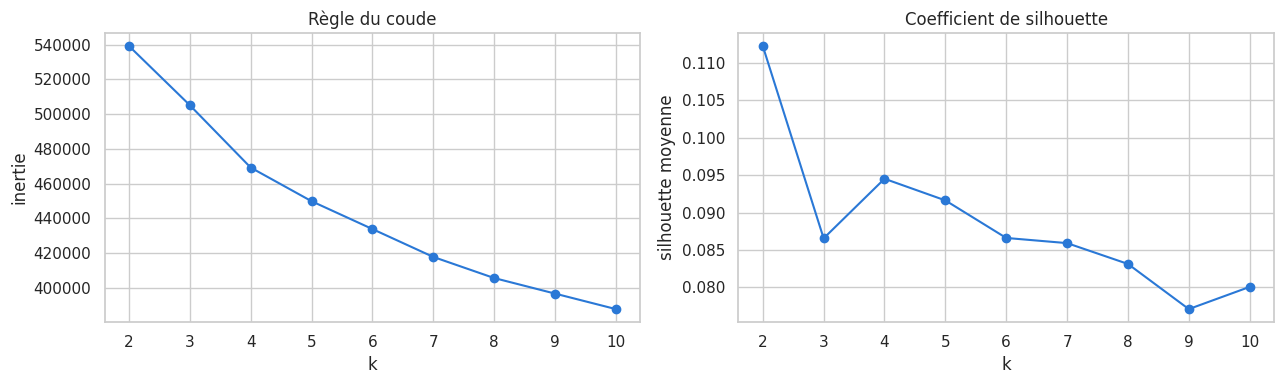

{2: np.float64(0.112), 3: np.float64(0.087), 4: np.float64(0.095), 5: np.float64(0.092), 6: np.float64(0.087), 7: np.float64(0.086), 8: np.float64(0.083), 9: np.float64(0.077), 10: np.float64(0.08)}


In [16]:
ks = range(2, 11)
inerties, sils = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=5, random_state=42).fit(Z)
    inerties.append(km.inertia_)
    sils.append(silhouette_score(Z.iloc[idx_s], km.labels_[idx_s]))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(ks, inerties, "o-", color=BLEU); ax[0].set(xlabel="k", ylabel="inertie", title="Règle du coude")
ax[1].plot(ks, sils, "o-", color=BLEU); ax[1].set(xlabel="k", ylabel="silhouette moyenne", title="Coefficient de silhouette")
plt.tight_layout(); plt.show()
print(dict(zip(ks, np.round(sils, 3))))

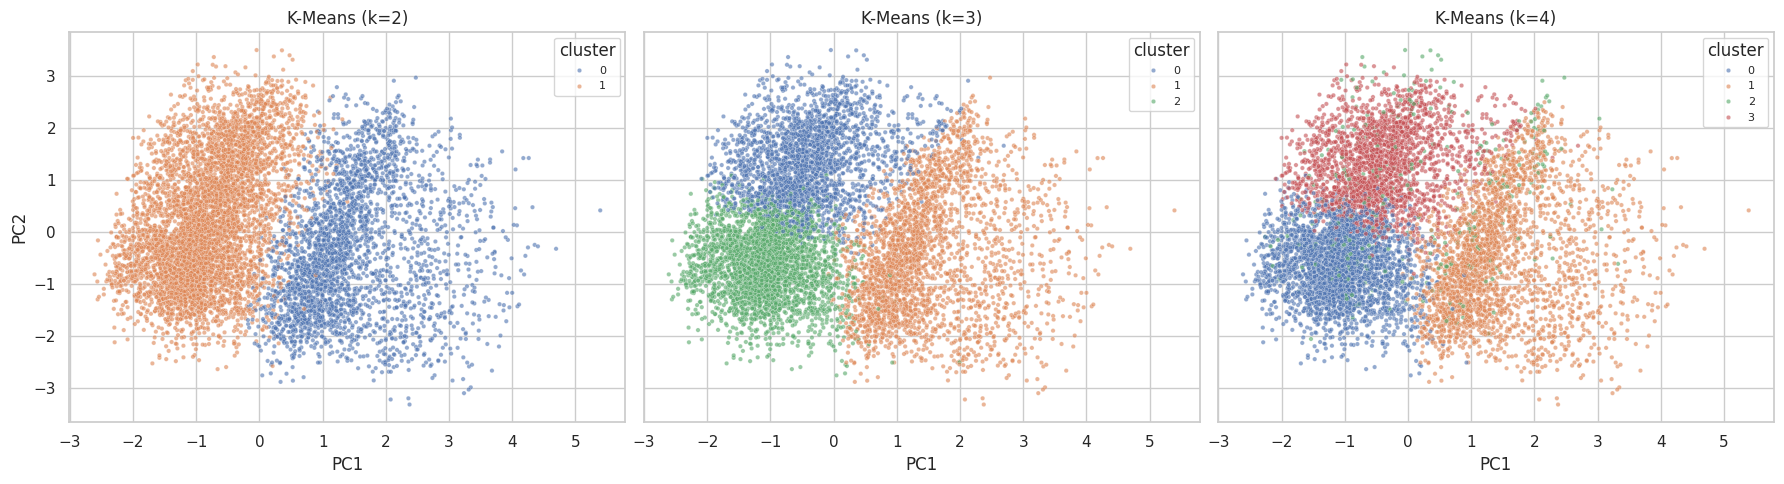


==================== k = 2 ====================
Taille des clusters : {0: 15563, 1: 28294}

Répartition de grav_max dans chaque cluster (%) :
grav_max  leger  hospitalise   tue
cluster                           
0          47.4         41.9  10.7
1          73.0         23.8   3.2

Information mutuelle normalisée clusters / grav_max : 0.047

Profil numérique (moyennes) :
           vma  age_cond_max  part_cond_hommes  part_cond_loisirs  \
cluster                                                             
0        85.93         47.24              0.76               0.55   
1        45.29         45.72              0.74               0.41   

         part_cond_proteges  
cluster                      
0                      0.96  
1                      0.96  

veh_vulnerable (% par cluster) :
veh_vulnerable  2rm_3rm  lourd  velo_edp  vl_vu
cluster                                        
0                  29.0    1.0       4.0   65.0
1                  33.0    2.0      21.0   44.0

a

In [19]:
KS = [2, 3, 4] # choisis après étude de la règle du coude et du coeficient de silouette
modeles = {k: KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z) for k in KS}

# Projections PCA
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)
for a, k in zip(axes, KS):
    sns.scatterplot(x=P[idx_s, 0], y=P[idx_s, 1], hue=modeles[k].labels_[idx_s],
                    palette="deep", s=10, alpha=0.6, ax=a)
    a.set(title=f"K-Means (k={k})", xlabel="PC1", ylabel="PC2")
    a.legend(title="cluster", fontsize=8)
plt.tight_layout(); plt.show()

# Statistiques pour chaque k
for k in KS:
    km_k = modeles[k]
    tc = train.assign(cluster=km_k.labels_)
    print(f"\n{'=' * 20} k = {k} {'=' * 20}")
    print("Taille des clusters :", tc["cluster"].value_counts().sort_index().to_dict())
    print("\nRépartition de grav_max dans chaque cluster (%) :")
    print((pd.crosstab(tc["cluster"], tc[TARGET], normalize="index") * 100).round(1))
    print("\nInformation mutuelle normalisée clusters / grav_max :",
          round(normalized_mutual_info_score(tc[TARGET].astype(str), km_k.labels_), 3))
    print("\nProfil numérique (moyennes) :")
    print(tc.groupby("cluster")[["vma", "age_cond_max", "part_cond_hommes",
                                 "part_cond_loisirs", "part_cond_proteges"]].mean().round(2))
    for c in ["veh_vulnerable", "agg", "catr"]:
        print(f"\n{c} (% par cluster) :")
        print((pd.crosstab(tc["cluster"], tc[c], normalize="index") * 100).round(0))
